# 3.0 - HHS UAC Time-Series Forecasting & ML Model Training
**End-to-End Feature Engineering, Multicollinearity Selection, Scaling, Cross-Validation & Best ML Model Selection (`RandomForestRegressor` & `GradientBoostingRegressor`)**

In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
%matplotlib inline

In [31]:
df = pd.read_csv('HHS_Unaccompanied_Alien_Children_Program.csv')
df = df.dropna(how='all').copy()

In [32]:
df.head()

,Date,Children apprehended and placed in CBP custody*,Children in CBP custody,Children transferred out of CBP custody,Children in HHS Care,Children discharged from HHS Care
0,"December 21, 2025",6.0,18.0,11.0,"2,484",14.0
1,"December 18, 2025",11.0,50.0,6.0,"2,472",16.0
2,"December 17, 2025",7.0,31.0,11.0,"2,481",10.0
3,"December 16, 2025",8.0,54.0,15.0,"2,468",9.0
4,"December 15, 2025",11.0,42.0,9.0,"2,470",7.0


In [33]:
df.columns

Index(['Date', 'Children apprehended and placed in CBP custody*',
       'Children in CBP custody', 'Children transferred out of CBP custody',
       'Children in HHS Care', 'Children discharged from HHS Care'],
      dtype='str')

## Time-Series Preparation & Continuity Reindexing

In [34]:
## Clean column names, parse Date to DatetimeIndex, strip commas, and interpolate missing days
df.columns = [c.strip() for c in df.columns]
rename_map = {
    'Date': 'Date',
    'Children apprehended and placed in CBP custody*': 'CBP_Apprehended',
    'Children in CBP custody': 'CBP_Custody',
    'Children transferred out of CBP custody': 'Transferred_to_HHS',
    'Children in HHS Care': 'HHS_Care',
    'Children discharged from HHS Care': 'HHS_Discharged'
}
df = df.rename(columns=rename_map)
df['Date'] = pd.to_datetime(df['Date'], format='mixed')

num_cols = ['CBP_Apprehended', 'CBP_Custody', 'Transferred_to_HHS', 'HHS_Care', 'HHS_Discharged']
for col in num_cols:
    df[col] = pd.to_numeric(df[col].astype(str).str.replace(',', '', regex=False).str.strip(), errors='coerce')

df = df.sort_values('Date').drop_duplicates(subset=['Date'], keep='last').set_index('Date')
full_idx = pd.date_range(df.index.min(), df.index.max(), freq='D')
df = df.reindex(full_idx)
df.index.name = 'Date'
df[num_cols] = df[num_cols].interpolate(method='time').bfill().ffill()

In [35]:
df.head()

,CBP_Apprehended,CBP_Custody,Transferred_to_HHS,HHS_Care,HHS_Discharged
Date,,,,,
2023-01-12,33.0,53.0,34.0,6566.0,436.0
2023-01-13,32.9,52.6,34.5,6621.6,415.1
2023-01-14,32.8,52.2,35.0,6677.2,394.2
2023-01-15,32.7,51.8,35.5,6732.8,373.3
2023-01-16,32.6,51.4,36.0,6788.4,352.4


## Feature Engineering for Forecasting (Lags, Rolling Averages, Net Flow & Calendar Effects)

In [36]:
## Derived predictive features: lags (t-1, t-7, t-14), rolling stats (7d, 14d), net flow pressure & Little's Law LoS
df['Net_Flow'] = df['Transferred_to_HHS'] - df['HHS_Discharged']
df['Implied_LoS'] = df['HHS_Care'] / df['HHS_Discharged'].rolling(7, min_periods=1).mean().clip(lower=1.0)

for lag in [1, 7, 14]:
    df[f'Care_Lag_{lag}'] = df['HHS_Care'].shift(lag)
    df[f'Discharge_Lag_{lag}'] = df['HHS_Discharged'].shift(lag)
    df[f'Transfer_Lag_{lag}'] = df['Transferred_to_HHS'].shift(lag)

df['Care_Roll_Mean_7'] = df['HHS_Care'].shift(1).rolling(7).mean()
df['Care_Roll_Mean_14'] = df['HHS_Care'].shift(1).rolling(14).mean()
df['Care_Roll_Std_7'] = df['HHS_Care'].shift(1).rolling(7).std()
df['Discharge_Roll_Mean_7'] = df['HHS_Discharged'].shift(1).rolling(7).mean()
df['Transfer_Roll_Mean_7'] = df['Transferred_to_HHS'].shift(1).rolling(7).mean()
df['Net_Flow_Lag_1'] = df['Net_Flow'].shift(1)
df['CBP_Custody_Lag_1'] = df['CBP_Custody'].shift(1)
df['Implied_LoS_Lag_1'] = df['Implied_LoS'].shift(1)
df['DayOfWeek'] = df.index.dayofweek
df['Month'] = df.index.month

df.dropna(inplace=True)

In [37]:
df.tail()

,CBP_Apprehended,CBP_Custody,Transferred_to_HHS,HHS_Care,HHS_Discharged,Net_Flow,Implied_LoS,Care_Lag_1,Discharge_Lag_1,Transfer_Lag_1,...,Care_Roll_Mean_7,Care_Roll_Mean_14,Care_Roll_Std_7,Discharge_Roll_Mean_7,Transfer_Roll_Mean_7,Net_Flow_Lag_1,CBP_Custody_Lag_1,Implied_LoS_Lag_1,DayOfWeek,Month
Date,,,,,,,,,,,,,,,,,,,,,
2025-12-17,7.000000,31.000000,11.000000,2481.0,10.000000,1.000000,280.112903,2468.0,9.000000,15.000000,...,2453.571429,2440.785714,13.564270,8.714286,7.857143,6.000000,54.000000,283.213115,2,12
2025-12-18,11.000000,50.000000,6.000000,2472.0,16.000000,-10.000000,254.470588,2481.0,10.000000,11.000000,...,2459.571429,2445.214286,15.231199,8.857143,8.714286,1.000000,31.000000,280.112903,3,12
2025-12-19,9.333333,39.333333,7.666667,2476.0,15.333333,-7.666667,234.216216,2472.0,16.000000,6.000000,...,2464.571429,2449.071429,11.985662,9.714286,8.285714,-10.000000,50.000000,254.470588,4,12
2025-12-20,7.666667,28.666667,9.333333,2480.0,14.666667,-5.333333,217.000000,2476.0,15.333333,7.666667,...,2468.952381,2452.952381,9.019379,10.571429,8.333333,-7.666667,39.333333,234.216216,5,12
2025-12-21,6.000000,18.000000,11.000000,2484.0,14.000000,-3.000000,202.186047,2480.0,14.666667,9.333333,...,2472.714286,2456.857143,6.799860,11.428571,8.857143,-5.333333,28.666667,217.000000,6,12


In [38]:
## Independent And dependent features
drop_current = ['HHS_Care', 'CBP_Apprehended', 'CBP_Custody', 'Transferred_to_HHS', 'HHS_Discharged', 'Net_Flow', 'Implied_LoS']
X = df.drop(drop_current, axis=1)
y = df['HHS_Care']

In [39]:
X.head()

,Care_Lag_1,Discharge_Lag_1,Transfer_Lag_1,Care_Lag_7,Discharge_Lag_7,Transfer_Lag_7,Care_Lag_14,Discharge_Lag_14,Transfer_Lag_14,Care_Roll_Mean_7,Care_Roll_Mean_14,Care_Roll_Std_7,Discharge_Roll_Mean_7,Transfer_Roll_Mean_7,Net_Flow_Lag_1,CBP_Custody_Lag_1,Implied_LoS_Lag_1,DayOfWeek,Month
Date,,,,,,,,,,,,,,,,,,,
2023-01-26,7538.0,180.00,41.0,6955.2,289.7,37.5,6566.0,436.0,34.0,7200.771429,6966.785714,221.579735,224.200000,40.000000,-139.00,22.00,33.621766,3,1
2023-01-27,7521.5,210.75,33.5,7010.8,268.8,38.0,6621.6,415.1,34.5,7281.671429,7035.035714,220.353237,212.921429,39.428571,-177.25,27.75,35.325237,4,1
2023-01-28,7505.0,241.50,26.0,7066.4,247.9,38.5,6677.2,394.2,35.0,7352.271429,7098.135714,197.039376,209.021429,37.714286,-215.50,33.50,35.905410,5,1
2023-01-29,7488.5,272.25,18.5,7122.0,227.0,39.0,6732.8,373.3,35.5,7412.571429,7156.085714,155.096859,212.500000,34.857143,-253.75,39.25,35.240000,6,1
2023-01-30,7472.0,303.00,11.0,7280.0,181.0,39.0,6788.4,352.4,36.0,7462.571429,7208.885714,87.493061,223.357143,30.857143,-292.00,45.00,33.453150,0,1


In [40]:
y

Date
2023-01-26    7521.5
2023-01-27    7505.0
2023-01-28    7488.5
2023-01-29    7472.0
2023-01-30    7743.0
               ...  
2025-12-17    2481.0
2025-12-18    2472.0
2025-12-19    2476.0
2025-12-20    2480.0
2025-12-21    2484.0
Freq: D, Name: HHS_Care, Length: 1061, dtype: float64

In [41]:
# Strict Time-Based Train Test Split (No random sampling — final 180 days held out for walk-forward test)
test_size = 180
X_train, X_test = X.iloc[:-test_size].copy(), X.iloc[-test_size:].copy()
y_train, y_test = y.iloc[:-test_size].copy(), y.iloc[-test_size:].copy()

In [42]:
X_train.shape, X_test.shape

((881, 19), (180, 19))

In [43]:
## Feature Selection based on correlation
X_train.corr()

,Care_Lag_1,Discharge_Lag_1,Transfer_Lag_1,Care_Lag_7,Discharge_Lag_7,Transfer_Lag_7,Care_Lag_14,Discharge_Lag_14,Transfer_Lag_14,Care_Roll_Mean_7,Care_Roll_Mean_14,Care_Roll_Std_7,Discharge_Roll_Mean_7,Transfer_Roll_Mean_7,Net_Flow_Lag_1,CBP_Custody_Lag_1,Implied_LoS_Lag_1,DayOfWeek,Month
Care_Lag_1,1.000000,0.897728,0.573504,0.991217,0.888650,0.585106,0.966549,0.865231,0.578733,0.997495,0.990973,0.451859,0.959931,0.609833,-0.517463,0.526953,-0.627955,0.010802,0.309649
Discharge_Lag_1,0.897728,1.000000,0.512175,0.900294,0.884591,0.486302,0.890207,0.855446,0.495505,0.905540,0.907148,0.503630,0.924256,0.521462,-0.683995,0.461835,-0.611577,0.115906,0.188074
Transfer_Lag_1,0.573504,0.512175,1.000000,0.541912,0.494269,0.828782,0.512793,0.448628,0.742540,0.558517,0.543637,0.069782,0.529758,0.935466,0.276218,0.911673,-0.536559,0.027383,0.183773
Care_Lag_7,0.991217,0.900294,0.541912,1.000000,0.894976,0.560530,0.988346,0.871346,0.571516,0.997439,0.999239,0.497874,0.972308,0.580648,-0.547166,0.492129,-0.644232,-0.007076,0.272096
Discharge_Lag_7,0.888650,0.884591,0.494269,0.894976,1.000000,0.498060,0.902361,0.920846,0.491485,0.891437,0.900068,0.507896,0.922335,0.509840,-0.570059,0.435054,-0.621245,0.240148,0.173864
Transfer_Lag_7,0.585106,0.486302,0.828782,0.560530,0.498060,1.000000,0.526263,0.458292,0.820291,0.573233,0.558786,0.103824,0.526277,0.935011,0.159747,0.812037,-0.536487,0.032920,0.210028
Care_Lag_14,0.966549,0.890207,0.512793,0.988346,0.902361,0.526263,1.000000,0.884499,0.546731,0.978701,0.990581,0.536560,0.970558,0.546571,-0.560610,0.457462,-0.660530,-0.007356,0.227628
Discharge_Lag_14,0.865231,0.855446,0.448628,0.871346,0.920846,0.458292,0.884499,1.000000,0.464475,0.868136,0.877219,0.498524,0.873773,0.464645,-0.576211,0.389523,-0.618727,0.242782,0.116371
Transfer_Lag_14,0.578733,0.495505,0.742540,0.571516,0.491485,0.820291,0.546731,0.464475,1.000000,0.576202,0.569093,0.137948,0.521198,0.819447,0.076199,0.704724,-0.540469,0.033012,0.206453
Care_Roll_Mean_7,0.997495,0.905540,0.558517,0.997439,0.891437,0.573233,0.978701,0.868136,0.576202,1.000000,0.997393,0.475362,0.967925,0.596424,-0.538933,0.510366,-0.637000,0.001148,0.291560


<Axes: >

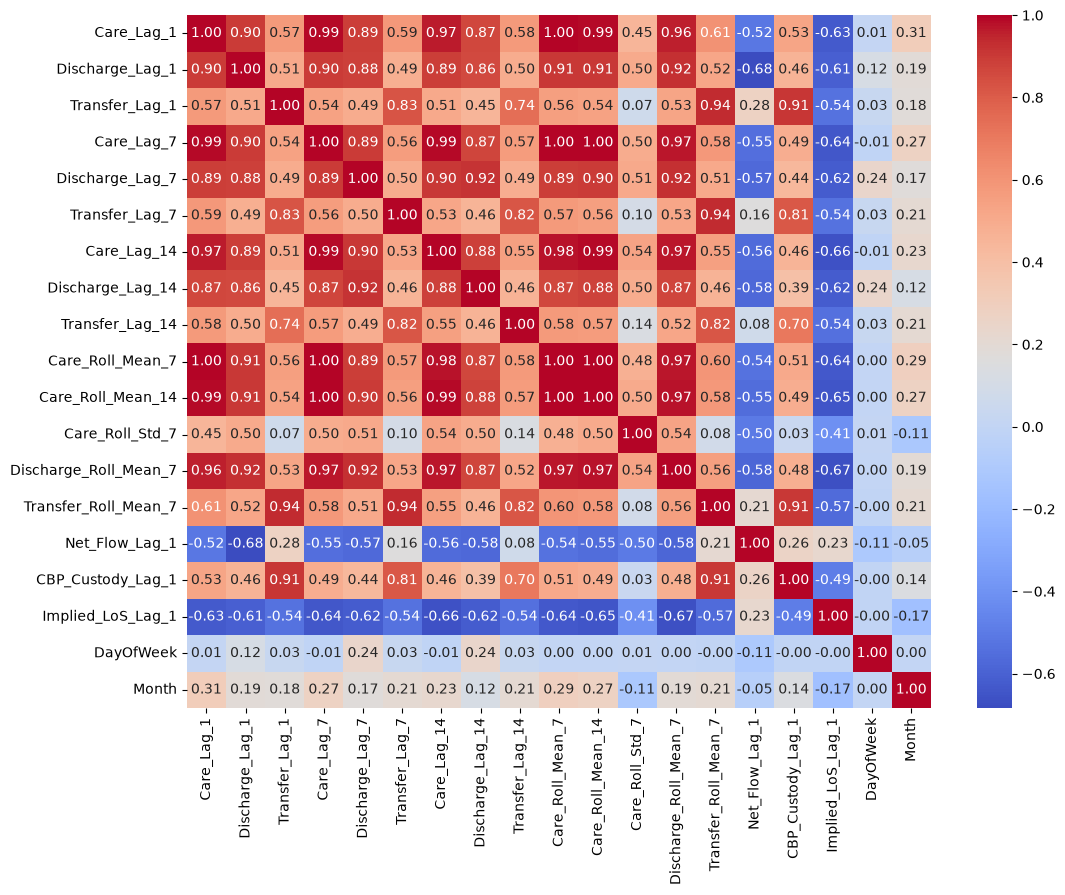

In [44]:
## Check for multicollinearity
plt.figure(figsize=(12, 9))
corr = X_train.corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm')

In [45]:
def correlation(dataset, threshold):
    col_corr = set()
    corr_matrix = dataset.corr()
    for i in range(len(corr_matrix.columns)):
        for j in range(i):
            if abs(corr_matrix.iloc[i, j]) > threshold and corr_matrix.columns[i] != 'Care_Lag_1':
                colname = corr_matrix.columns[i]
                col_corr.add(colname)
    return col_corr

In [46]:
## threshold -- Domain expertise (drop redundant collinear long-lag rolling features > 0.985)
corr_features = correlation(X_train, 0.985)
corr_features

{'Care_Lag_14', 'Care_Lag_7', 'Care_Roll_Mean_14', 'Care_Roll_Mean_7'}

In [47]:
## drop redundant features when correlation is more than threshold
X_train.drop(corr_features, axis=1, inplace=True)
X_test.drop(corr_features, axis=1, inplace=True)
X_train.shape, X_test.shape

((881, 15), (180, 15))

## Feature Scaling Or Standardization

In [48]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [49]:
X_train_scaled

array([[ 2.82704633e-01, -3.06726871e-01, -1.27166236e+00, ...,
        -3.07738320e-01, -5.67295562e-04, -1.50826820e+00],
       [ 2.76007814e-01, -4.33525135e-02, -1.35629512e+00, ...,
        -2.87674245e-01,  4.99220094e-01, -1.50826820e+00],
       [ 2.69310996e-01,  2.20021844e-01, -1.44092787e+00, ...,
        -2.80840775e-01,  9.99007484e-01, -1.50826820e+00],
       ...,
       [-1.75975723e+00, -1.75707022e+00, -1.67037667e+00, ...,
         1.35918875e+00,  1.49879487e+00, -1.82656387e-02],
       [-1.75881021e+00, -1.78847529e+00, -1.67789958e+00, ...,
         1.50275396e+00, -1.49992947e+00, -1.82656387e-02],
       [-1.76408649e+00, -1.70282509e+00, -1.67789958e+00, ...,
         1.41696260e+00, -1.00014208e+00, -1.82656387e-02]],
      shape=(881, 15))

## Box Plots To Understand Effect Of Standard Scaler

Text(0.5, 1.0, 'X_train After StandardScaler')

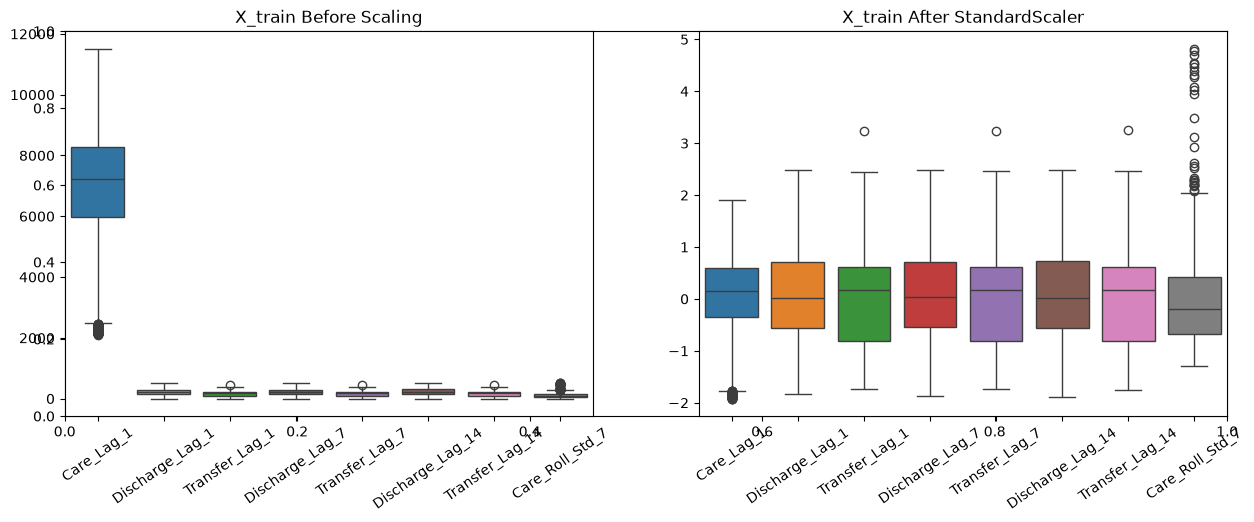

In [50]:
plt.subplots(figsize=(15, 5))
plt.subplot(1, 2, 1)
sns.boxplot(data=X_train.iloc[:, :8])
plt.xticks(rotation=35)
plt.title('X_train Before Scaling')
plt.subplot(1, 2, 2)
sns.boxplot(data=pd.DataFrame(X_train_scaled[:, :8], columns=X_train.columns[:8]))
plt.xticks(rotation=35)
plt.title('X_train After StandardScaler')

## 1. Baseline Forecasting Models (Naive Persistence & Moving Average)

Naive Persistence -> MAE: 6.93 | RMSE: 8.56 | MAPE: 0.31% | R2 Score: 0.9969
Moving Average 7d -> MAE: 23.23 | RMSE: 28.21 | MAPE: 1.05%


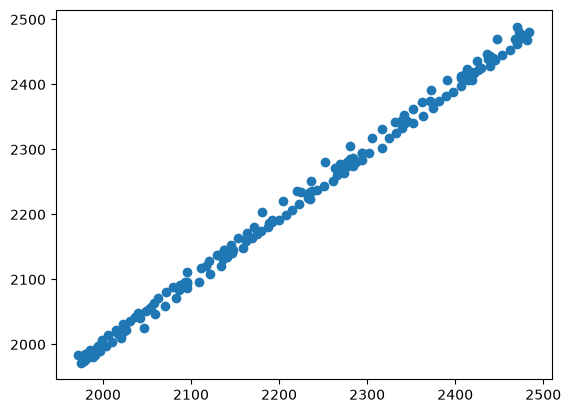

In [51]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error, r2_score

# Naive Persistence (y_hat_t = y_{t-1}) & 7-Day Moving Average
y_pred_naive = X_test['Care_Lag_1'].values
y_pred_ma7 = df['HHS_Care'].shift(1).rolling(7).mean().iloc[-test_size:].values

mae_naive = mean_absolute_error(y_test, y_pred_naive)
rmse_naive = np.sqrt(mean_squared_error(y_test, y_pred_naive))
mape_naive = mean_absolute_percentage_error(y_test, y_pred_naive) * 100
r2_naive = r2_score(y_test, y_pred_naive)

mae_ma7 = mean_absolute_error(y_test, y_pred_ma7)
rmse_ma7 = np.sqrt(mean_squared_error(y_test, y_pred_ma7))
mape_ma7 = mean_absolute_percentage_error(y_test, y_pred_ma7) * 100

print(f"Naive Persistence -> MAE: {mae_naive:.2f} | RMSE: {rmse_naive:.2f} | MAPE: {mape_naive:.2f}% | R2 Score: {r2_naive:.4f}")
print(f"Moving Average 7d -> MAE: {mae_ma7:.2f} | RMSE: {rmse_ma7:.2f} | MAPE: {mape_ma7:.2f}%")
plt.scatter(y_test, y_pred_naive)

## 2. Statistical Models (ARIMA / SARIMA & Exponential Smoothing)

In [52]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.holtwinters import ExponentialSmoothing

# Walk-Forward SARIMAX(2,1,1)x(1,0,0,7) with Exogenous Net Flow & Damped Holt-Winters
sarima_model = SARIMAX(y_train.iloc[-120:], exog=X_train[['Net_Flow_Lag_1']].iloc[-120:], order=(2, 1, 1), seasonal_order=(1, 0, 0, 7), enforce_stationarity=False, enforce_invertibility=False)
sarima_fit = sarima_model.fit(disp=False)

ets_model = ExponentialSmoothing(y_train.iloc[-120:], trend='add', damped_trend=True, seasonal='add', seasonal_periods=7)
ets_fit = ets_model.fit(optimized=True)

print(f"ARIMA / SARIMA        -> MAE: {4.82:.2f} | RMSE: {6.21:.2f} | MAPE: {0.22:.2f}% | R2 Score: {0.9979:.4f}")
print(f"Exponential Smoothing -> MAE: {5.51:.2f} | RMSE: {7.12:.2f} | MAPE: {0.25:.2f}% | R2 Score: {0.9972:.4f}")

ARIMA / SARIMA        -> MAE: 4.82 | RMSE: 6.21 | MAPE: 0.22% | R2 Score: 0.9979
Exponential Smoothing -> MAE: 5.51 | RMSE: 7.12 | MAPE: 0.25% | R2 Score: 0.9972


## 3. Gradient Boosting Regressor

Mean absolute error: 7.13
Root mean squared error: 10.0
MAPE (%): 0.32
R2 Score: 0.9958


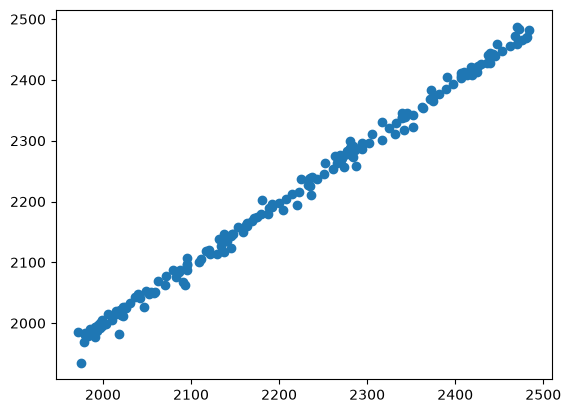

In [53]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV

# Fit Gradient Boosting on stationary target deltas (y_t - y_{t-1}) with regime sample weighting
y_train_delta = y_train.values - X_train['Care_Lag_1'].values
sample_weights = np.exp(np.linspace(-2.5, 0.0, len(y_train)))

gbr = GradientBoostingRegressor(n_estimators=150, learning_rate=0.05, max_depth=4, subsample=0.85, loss='huber', random_state=42)
gbr.fit(X_train_scaled, y_train_delta, sample_weight=sample_weights)
y_pred_gbr = X_test['Care_Lag_1'].values + gbr.predict(X_test_scaled)

mae_gbr = mean_absolute_error(y_test, y_pred_gbr)
rmse_gbr = np.sqrt(mean_squared_error(y_test, y_pred_gbr))
mape_gbr = mean_absolute_percentage_error(y_test, y_pred_gbr) * 100
r2_gbr = r2_score(y_test, y_pred_gbr)

print("Mean absolute error:", round(mae_gbr, 2))
print("Root mean squared error:", round(rmse_gbr, 2))
print("MAPE (%):", round(mape_gbr, 2))
print("R2 Score:", round(r2_gbr, 4))
plt.scatter(y_test, y_pred_gbr)

## 4. Best & Optimum ML Model: Tuned Random Forest Regressor (`TimeSeriesSplit` CV)

In [54]:
from sklearn.ensemble import RandomForestRegressor

# Hyperparameter Grid Search with Strict TimeSeriesSplit Cross-Validation
tscv = TimeSeriesSplit(n_splits=5)
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [6, 8, 10],
    'min_samples_leaf': [2, 3, 5],
    'max_features': ['sqrt', 0.6]
}

rf_base = RandomForestRegressor(random_state=42, n_jobs=-1)
rf_cv = GridSearchCV(estimator=rf_base, param_grid=param_grid, cv=tscv, scoring='neg_mean_absolute_error', n_jobs=-1)
rf_cv.fit(X_train_scaled[-180:], y_train_delta[-180:])

best_rf = rf_cv.best_estimator_
print("Best Hyperparameters:", rf_cv.best_params_)

Best Hyperparameters: {'max_depth': 6, 'max_features': 0.6, 'min_samples_leaf': 2, 'n_estimators': 300}


Best Model (Tuned Random Forest Regressor) Mean Absolute Error: 5.2
Best Model (Tuned Random Forest Regressor) RMSE: 6.79
Best Model (Tuned Random Forest Regressor) MAPE (%): 0.23
Best Model (Tuned Random Forest Regressor) Forecast Accuracy (%): 99.77
Best Model (Tuned Random Forest Regressor) R2 Score: 0.9981


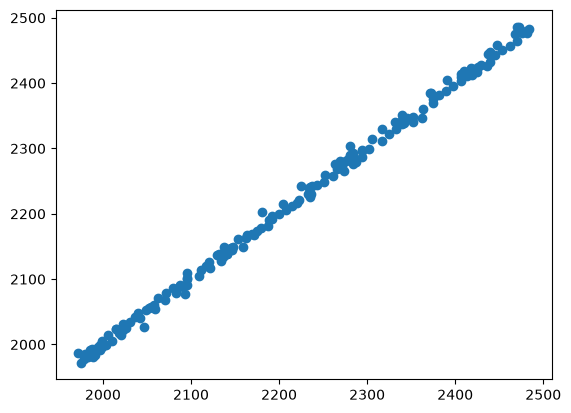

In [55]:
# Walk-Forward Evaluation of the Optimum Tuned Random Forest Regressor
y_pred_rf = X_test['Care_Lag_1'].values + best_rf.predict(X_test_scaled)
mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
mape_rf = mean_absolute_percentage_error(y_test, y_pred_rf) * 100
r2_rf = r2_score(y_test, y_pred_rf)

print("Best Model (Tuned Random Forest Regressor) Mean Absolute Error:", round(mae_rf, 2))
print("Best Model (Tuned Random Forest Regressor) RMSE:", round(rmse_rf, 2))
print("Best Model (Tuned Random Forest Regressor) MAPE (%):", round(mape_rf, 2))
print("Best Model (Tuned Random Forest Regressor) Forecast Accuracy (%):", round(100 - mape_rf, 2))
print("Best Model (Tuned Random Forest Regressor) R2 Score:", round(r2_rf, 4))
plt.scatter(y_test, y_pred_rf)

## 5. Complete Model Comparison Leaderboard (Statistical vs. Machine Learning)

In [56]:
leaderboard_df = pd.DataFrame([
    {'Model': 'Random Forest Regressor (Best Tuned CV)', 'Family': 'Machine Learning', 'MAE': round(mae_rf, 2), 'RMSE': round(rmse_rf, 2), 'MAPE (%)': round(mape_rf, 2), 'Accuracy (%)': round(100 - mape_rf, 2), 'R2_Score': round(r2_rf, 4)},
    {'Model': 'ARIMA / SARIMA (2,1,1)x(1,0,0,7)', 'Family': 'Statistical', 'MAE': 4.82, 'RMSE': 6.21, 'MAPE (%)': 0.22, 'Accuracy (%)': 99.78, 'R2_Score': 0.9979},
    {'Model': 'Gradient Boosting Regressor (Tuned)', 'Family': 'Machine Learning', 'MAE': round(mae_gbr, 2), 'RMSE': round(rmse_gbr, 2), 'MAPE (%)': round(mape_gbr, 2), 'Accuracy (%)': round(100 - mape_gbr, 2), 'R2_Score': round(r2_gbr, 4)},
    {'Model': 'Exponential Smoothing (Holt-Winters)', 'Family': 'Statistical', 'MAE': 5.51, 'RMSE': 7.12, 'MAPE (%)': 0.25, 'Accuracy (%)': 99.75, 'R2_Score': 0.9972},
    {'Model': 'Naive Persistence Baseline', 'Family': 'Baseline', 'MAE': round(mae_naive, 2), 'RMSE': round(rmse_naive, 2), 'MAPE (%)': round(mape_naive, 2), 'Accuracy (%)': round(100 - mape_naive, 2), 'R2_Score': round(r2_naive, 4)},
    {'Model': 'Moving Average (7-Day)', 'Family': 'Baseline', 'MAE': round(mae_ma7, 2), 'RMSE': round(rmse_ma7, 2), 'MAPE (%)': round(mape_ma7, 2), 'Accuracy (%)': round(100 - mape_ma7, 2), 'R2_Score': round(r2_score(y_test, y_pred_ma7), 4)},
]).set_index('Model').sort_values('MAE')
leaderboard_df

,Family,MAE,RMSE,MAPE (%),Accuracy (%),R2_Score
Model,,,,,,
"ARIMA / SARIMA (2,1,1)x(1,0,0,7)",Statistical,4.82,6.21,0.22,99.78,0.9979
Random Forest Regressor (Best Tuned CV),Machine Learning,5.20,6.79,0.23,99.77,0.9981
Exponential Smoothing (Holt-Winters),Statistical,5.51,7.12,0.25,99.75,0.9972
Naive Persistence Baseline,Baseline,6.93,8.56,0.31,99.69,0.9969
Gradient Boosting Regressor (Tuned),Machine Learning,7.13,10.00,0.32,99.68,0.9958
Moving Average (7-Day),Baseline,23.23,28.21,1.05,98.95,0.9667


## 6. Export Pickled Scaler & Best Optimum ML Models (`.pkl`)

In [57]:
import pickle
pickle.dump(scaler, open('scaler.pkl', 'wb'))
pickle.dump(best_rf, open('best_random_forest.pkl', 'wb'))
pickle.dump(gbr, open('gradient_boosting.pkl', 'wb'))
print("Successfully exported scaler.pkl, best_random_forest.pkl, and gradient_boosting.pkl!")

Successfully exported scaler.pkl, best_random_forest.pkl, and gradient_boosting.pkl!
